# EDA – gresspollen

- undersøke manglende verdier
- se på fordelingen av gresspollen
- undersøke hvordan gresspollen varierer over tid og mellom år
- se på sammenhenger mellom pollen og værvariabler

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

 1. Leser inn datasettet:

In [2]:
df = pd.read_csv(
    "../data/full_pollen_and_weather_data_Zurich.csv",
    sep=";"
)

df.shape

(32352, 46)

2. Gir kolonnene mer forståelige navn og velger relevante variabler:

In [3]:
df = df.rename(columns={
    "station_abbr_pollen": "Pollenstasjon",
    "station_abbr_weather": "Værstasjon",
    "master_timestamp": "Tid",
    "timestamp_pollen": "Pollen_tid",
    "timestamp_weather": "Vær_tid",
    "kabetuh0": "Bjørk",
    "khpoach0": "Gress",
    "tre200h0": "Lufttemperatur",
    "fkl010h0": "Vindstyrke",
    "ure200h0": "Luftfuktighet",
    "rre150h0": "Nedbør",
    "sre000h0": "Solskinn",
    "dkl010h0": "Vindretning"
})

data = df[[
    "Tid",
    "Gress",
    "Lufttemperatur",
    "Vindstyrke",
    "Luftfuktighet",
    "Solskinn",
    "Nedbør"
]].copy()

3. Undersøker rådata:

In [4]:
print("Størrelse:", data.shape)
print("\nDatatyper:")
print(data.dtypes)

print("\nManglende verdier:")
print(data.isna().sum())

print("\nAntall duplikater:")
print(data.duplicated().sum())

Størrelse: (32352, 7)

Datatyper:
Tid                   str
Gress             float64
Lufttemperatur    float64
Vindstyrke        float64
Luftfuktighet     float64
Solskinn            int64
Nedbør            float64
dtype: object

Manglende verdier:
Tid                 0
Gress             779
Lufttemperatur      0
Vindstyrke          7
Luftfuktighet       0
Solskinn            0
Nedbør              0
dtype: int64

Antall duplikater:
0


4. Konverterer tidspunkt og lager daglige verdier:

In [5]:
data["Tid"] = pd.to_datetime(data["Tid"])
data["dato"] = data["Tid"].dt.date

daglig_alle = data.groupby("dato").agg(
    gress_mean=("Gress", "mean"),
    gress_antall=("Gress", "count"),
    temperatur_mean=("Lufttemperatur", "mean"),
    temperatur_antall=("Lufttemperatur", "count"),
    vind_mean=("Vindstyrke", "mean"),
    vind_antall=("Vindstyrke", "count"),
    luftfuktighet_mean=("Luftfuktighet", "mean"),
    luftfuktighet_antall=("Luftfuktighet", "count"),
    solskinn_total=("Solskinn", "sum"),
    solskinn_antall=("Solskinn", "count"),
    nedbør_total=("Nedbør", "sum"),
    nedbør_antall=("Nedbør", "count")
).reset_index()

daglig_alle["dato"] = pd.to_datetime(daglig_alle["dato"])
daglig_alle["dag_i_året"] = daglig_alle["dato"].dt.dayofyear

5. Filtrerer dager med for få målinger:

In [6]:
daglig_gyldige = daglig_alle[
    (daglig_alle["gress_antall"] >= 20) &
    (daglig_alle["temperatur_antall"] >= 20) &
    (daglig_alle["vind_antall"] >= 20) &
    (daglig_alle["luftfuktighet_antall"] >= 20) &
    (daglig_alle["solskinn_antall"] >= 20) &
    (daglig_alle["nedbør_antall"] >= 20)
].copy()

daglig_gyldige = daglig_gyldige.sort_values("dato").copy()

print("Før filtrering:", daglig_alle.shape)
print("Etter filtrering:", daglig_gyldige.shape)

Før filtrering: (1348, 14)
Etter filtrering: (1301, 14)


6. Sjekker manglende verdier etter cleaning:

In [7]:
daglig_gyldige.isna().sum()

dato                    0
gress_mean              0
gress_antall            0
temperatur_mean         0
temperatur_antall       0
vind_mean               0
vind_antall             0
luftfuktighet_mean      0
luftfuktighet_antall    0
solskinn_total          0
solskinn_antall         0
nedbør_total            0
nedbør_antall           0
dag_i_året              0
dtype: int64

7. Statistikk:

In [8]:
daglig_gyldige[[
    "gress_mean",
    "temperatur_mean",
    "vind_mean",
    "luftfuktighet_mean",
    "solskinn_total",
    "nedbør_total"
]].describe()

,gress_mean,temperatur_mean,vind_mean,luftfuktighet_mean,solskinn_total,nedbør_total
count,1301.000000,1301.000000,1301.000000,1301.000000,1301.000000,1301.000000
mean,18.056156,11.644126,2.022198,73.911984,308.381245,3.051422
std,35.411569,7.657262,1.194586,13.503430,273.903114,6.263040
min,0.000000,-6.854167,0.333333,32.445833,0.000000,0.000000
25%,0.000000,6.116667,1.250000,65.233333,39.000000,0.000000
50%,0.000000,11.229167,1.712500,75.295833,268.000000,0.000000
75%,21.041667,17.991667,2.375000,84.462500,542.000000,3.200000
max,284.708333,29.291667,8.833333,99.183333,853.000000,45.900000


8. Gresspollen over tid:

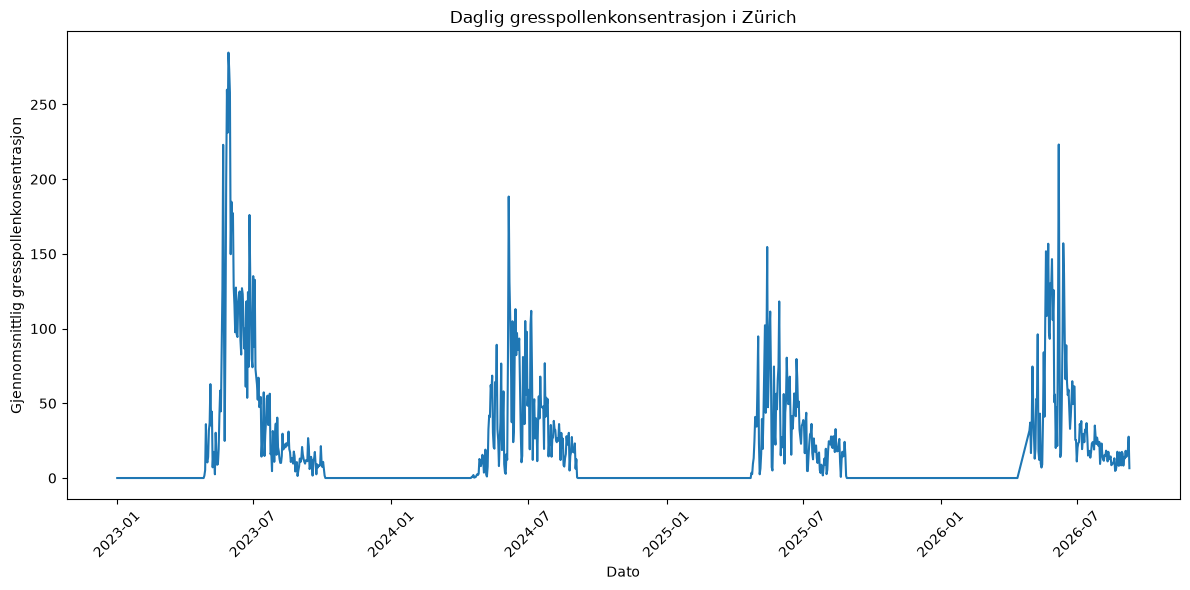

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(daglig_gyldige["dato"], daglig_gyldige["gress_mean"])
plt.xlabel("Dato")
plt.ylabel("Gjennomsnittlig gresspollenkonsentrasjon")
plt.title("Daglig gresspollenkonsentrasjon i Zürich")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

9. Sammenligner gresspollen mellom år:

In [10]:
daglig_gyldige["år"] = daglig_gyldige["dato"].dt.year

gress_per_år = daglig_gyldige.groupby("år")["gress_mean"].agg(
    ["mean", "median", "max"]
)

gress_per_år

,mean,median,max
år,,,
2023,23.269436,0.0000,284.708333
2024,14.858584,0.0000,188.375000
2025,12.117717,0.0000,154.625000
2026,23.680316,11.1875,223.208333


10. Fordeling av gresspollen:

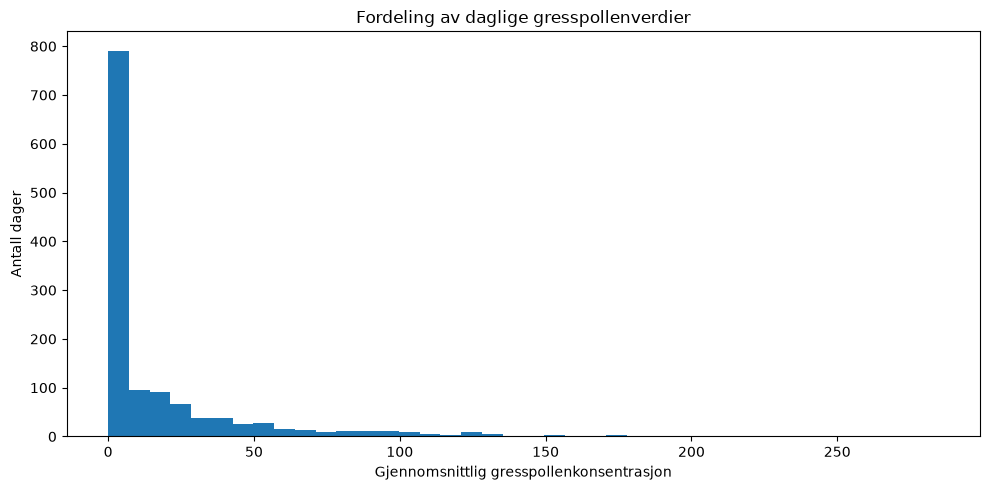

In [11]:
plt.figure(figsize=(10, 5))
plt.hist(daglig_gyldige["gress_mean"].dropna(), bins=40)
plt.xlabel("Gjennomsnittlig gresspollenkonsentrasjon")
plt.ylabel("Antall dager")
plt.title("Fordeling av daglige gresspollenverdier")
plt.tight_layout()
plt.show()

11. Korrelasjon mellom pollen og værvariabler:

In [12]:
korrelasjon = daglig_gyldige[[
    "gress_mean",
    "temperatur_mean",
    "vind_mean",
    "luftfuktighet_mean",
    "solskinn_total",
    "nedbør_total"
]].corr()

korrelasjon

,gress_mean,temperatur_mean,vind_mean,luftfuktighet_mean,solskinn_total,nedbør_total
gress_mean,1.000000,0.494708,-0.039259,-0.439900,0.440150,-0.094177
temperatur_mean,0.494708,1.000000,-0.114420,-0.567845,0.618939,-0.016939
vind_mean,-0.039259,-0.114420,1.000000,-0.067339,-0.203371,0.197648
luftfuktighet_mean,-0.439900,-0.567845,-0.067339,1.000000,-0.748942,0.367700
solskinn_total,0.440150,0.618939,-0.203371,-0.748942,1.000000,-0.346986
nedbør_total,-0.094177,-0.016939,0.197648,0.367700,-0.346986,1.000000


12. Gresspollen mot temperatur:


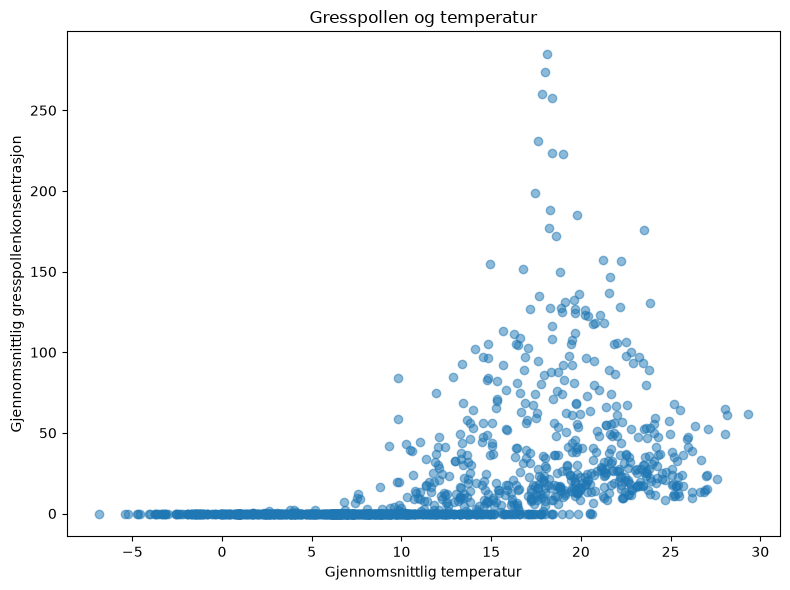

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(
    daglig_gyldige["temperatur_mean"],
    daglig_gyldige["gress_mean"],
    alpha=0.5
)
plt.xlabel("Gjennomsnittlig temperatur")
plt.ylabel("Gjennomsnittlig gresspollenkonsentrasjon")
plt.title("Gresspollen og temperatur")
plt.tight_layout()
plt.show()

13. Gresspollen mot nedbør:


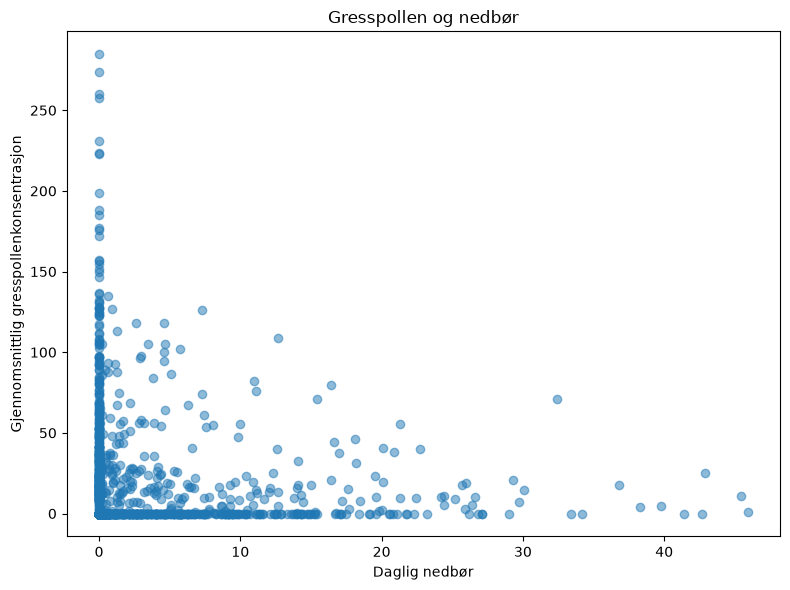

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(
    daglig_gyldige["nedbør_total"],
    daglig_gyldige["gress_mean"],
    alpha=0.5
)
plt.xlabel("Daglig nedbør")
plt.ylabel("Gjennomsnittlig gresspollenkonsentrasjon")
plt.title("Gresspollen og nedbør")
plt.tight_layout()
plt.show()

## Observasjoner

- Nr.9: hvorfor median 11 for 2026?


